# Adding the needed libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Adding and editting the document 

Reading the initial data and editing it to become usable for analysis. (to practice with :) )
* Replacing the numbering index with characters name.
* Making a smaller dataset by cutting some columns off.

In [2]:
df = pd.read_csv("/kaggle/input/datasets/jonathanaveo/genshin-characters-list-and-tier-7-1/Genshin Characters List 7.1 .csv")
'''columns ['character_name', 'gender', 'model_type', 'rarity', 'region', 
            'element','weapon_type', 'constellation_name', 'birthday', 'special_dish',
            'ascension_stat', 'date_released', 'release_version', 'tier_rating', 'primary_role']'''

def extract_region(value):
    if pd.isna(value):
        return value

    if "(in-game)" in value and "(in lore)" in value:
        return value.split("(in-game)")[1].split("(in lore)")[0].strip()
    return value

df.set_index('character_name', inplace=True)
df["region"] = df["region"].apply(extract_region)
dfPartial = df.drop(['model_type','constellation_name', 'birthday', 'special_dish','ascension_stat', 'date_released', 'primary_role'], axis = 1 )

dfPartial.head()

,gender,rarity,region,element,weapon_type,release_version,tier_rating
character_name,,,,,,,
Zibai,Female,5-star,Liyue,Geo,Sword,6.3,SS
Klee,Female,5-star,Mondstadt,Pyro,Catalyst,1.0,A
Razor,Male,4-star,Mondstadt,Electro,Claymore,1.0,B
Tartaglia,Male,5-star,Snezhnaya,Hydro,Bow,1.1,B
Yae Miko,Female,5-star,Inazuma,Electro,Catalyst,2.5,SS


# Making the plot

1. A bar plot that shows the number of characters for each region.

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Mondstadt'),
  Text(1, 0, 'Liyue'),
  Text(2, 0, 'Inazuma'),
  Text(3, 0, 'Sumeru'),
  Text(4, 0, 'Fontaine'),
  Text(5, 0, 'Natlan'),
  Text(6, 0, 'Nod-Krai'),
  Text(7, 0, 'Snezhnaya'),
  Text(8, 0, "Khaenri'ah"),
  Text(9, 0, 'Simulanka')])

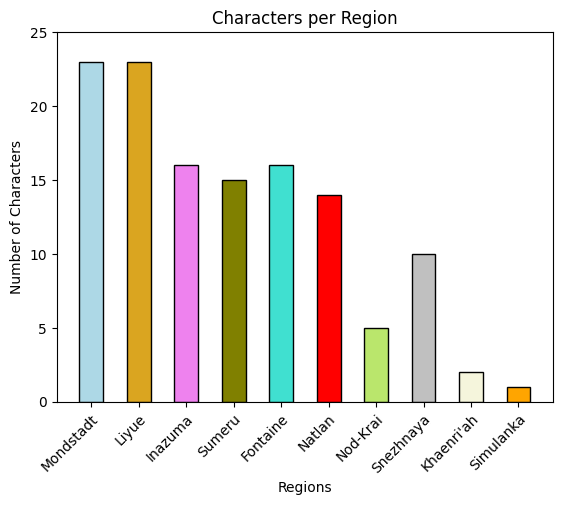

In [3]:
Regions = ['Mondstadt', 'Liyue', 'Inazuma', 'Sumeru', 'Fontaine', 
           'Natlan', 'Nod-Krai', 'Snezhnaya', "Khaenri'ah", 'Simulanka']

CharacterCount = dfPartial['region'].value_counts()  
#output is a series with index as region and values as count of characters in that region
CharacterCount = CharacterCount.reindex(Regions)
#reindexing to make sure the order of regions is correct

CharactersPerRegion = plt.bar(CharacterCount.index, CharacterCount.values, width = 0.5, edgecolor = 'black',  
        color = [ 'lightblue', 'goldenrod', 'violet', 'olive', 'turquoise', 'red', '#BAE66C', 'silver', 'beige', 'orange'])

plt.title('Characters per Region')
plt.xlabel('Regions')
plt.ylabel('Number of Characters')
plt.axis(ymax = 25)
plt.xticks(fontsize=10, rotation=45, ha='right', rotation_mode='anchor')

2. A pie plot that shows the number of characters for each element.

Text(0.5, 1.0, 'Characters per Element')

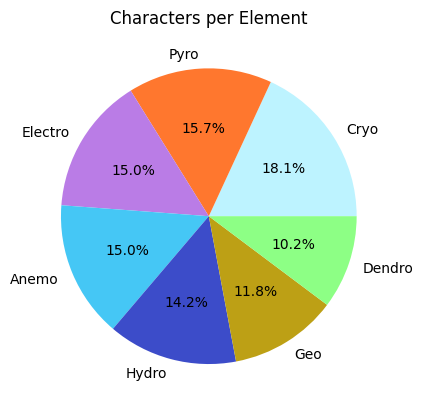

In [4]:
ElementTypes = dfPartial['element'].value_counts()

plt.pie( ElementTypes.values , labels = ElementTypes.index, autopct='%1.1f%%', 
                colors = ['#BDF3FF', '#FF772E', '#BA7CE6', '#45C7F5', '#3C4CC9', '#BDA015', '#8DFF85'])

plt.title('Characters per Element')

3. A barh plot number of characters that use each type of weapon

Text(0, 0.5, 'Weapon')

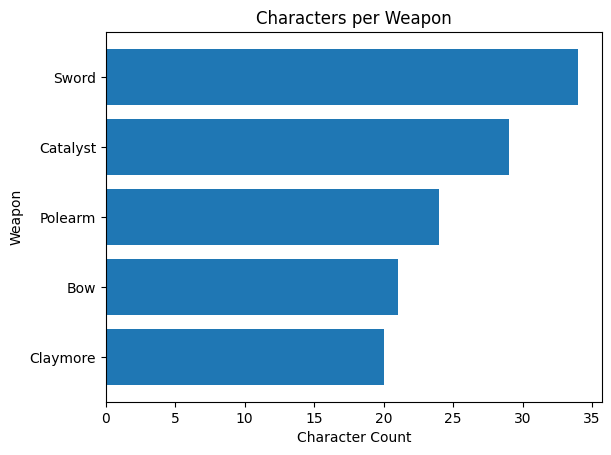

In [5]:
WeaponTypes = dfPartial['weapon_type'].value_counts().sort_values()

CharactersPerWeapon = plt.barh(WeaponTypes.index, WeaponTypes.values)

plt.title('Characters per Weapon')
plt.xlabel('Character Count')
plt.ylabel('Weapon')

4. A bar plot of the number of characters released in each release_version 

Text(0, 0.5, 'Character Count')

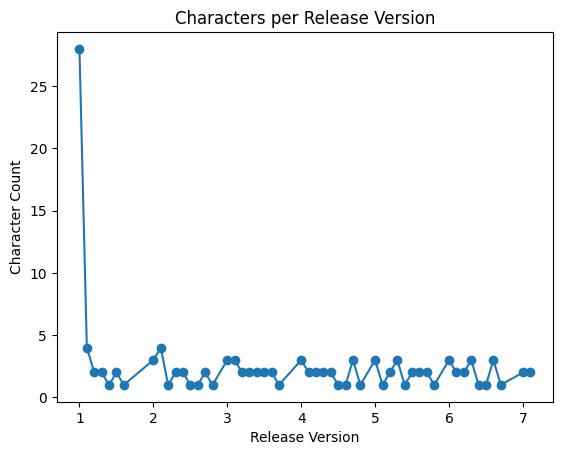

In [6]:
version_counts = df.groupby('release_version').size().sort_index()

plt.plot( version_counts.index, version_counts.values, marker = 'o')

plt.title('Characters per Release Version')
plt.xlabel('Release Version')
plt.ylabel('Character Count')

5. Working with subplot

([0, 1, 2, 3, 4],
 [Text(0, 0, 'Sword'),
  Text(1, 0, 'Catalyst'),
  Text(2, 0, 'Polearm'),
  Text(3, 0, 'Bow'),
  Text(4, 0, 'Claymore')])

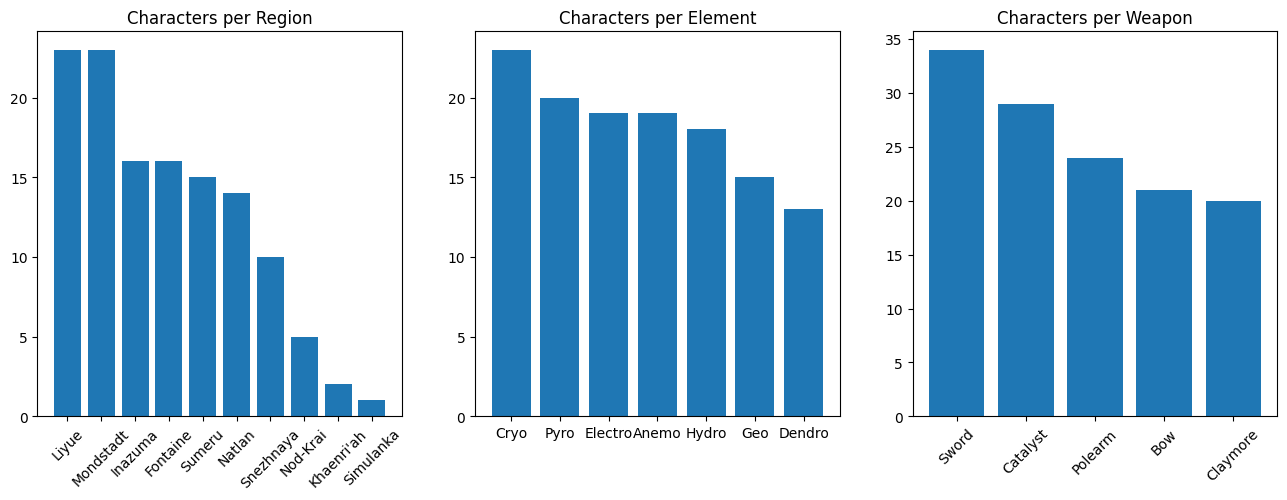

In [7]:
plt.figure(figsize=(16, 5))

region_counts = dfPartial['region'].value_counts()
element_counts = dfPartial['element'].value_counts()
weapon_counts = dfPartial['weapon_type'].value_counts()

plt.subplot(1, 3, 1)
plt.bar(region_counts.index, region_counts.values)
plt.title('Characters per Region')
plt.xticks(rotation=45)

plt.subplot(1, 3, 2)
plt.bar(element_counts.index, element_counts.values)
plt.title('Characters per Element')

plt.subplot(1, 3, 3)
plt.bar(weapon_counts.index, weapon_counts.values)
plt.title('Characters per Weapon')
plt.xticks(rotation=45)


6. Element Distribution per Version

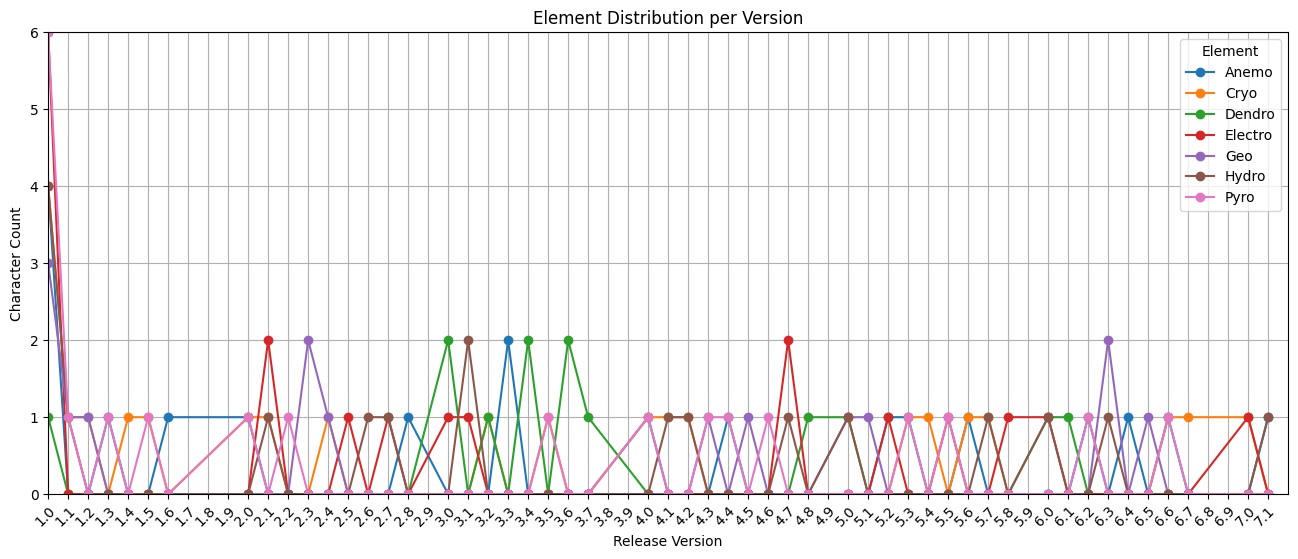

In [8]:
element_version = pd.crosstab( df['release_version'], df['element'] )

Plot = element_version.plot(kind='line', marker='o', figsize=(16, 6))

plt.title('Element Distribution per Version')
plt.xlabel('Release Version')
plt.ylabel('Character Count')

Plot.set_xlim(1, 7.2)
Plot.set_ylim(0, 6)

plt.xticks(np.arange(1, 7.2, 0.1))
plt.xticks(fontsize=10, rotation=45, ha='right', rotation_mode='anchor')

plt.legend( title = 'Element' )
plt.grid()